<a href="https://colab.research.google.com/github/SnehaGupta359/first-demo/blob/main/decision_tree_algo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [12]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)


In [13]:

df = pd.read_csv("/content/Breast_Cancer.csv")

# Remove extra spaces from column names
df.columns = df.columns.str.strip()

# Display dataset
print(df.head())

# Dataset information
print("\nDataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())


   Age   Race Marital Status T Stage N Stage 6th Stage  \
0   68  White        Married      T1      N1       IIA   
1   50  White        Married      T2      N2      IIIA   
2   58  White       Divorced      T3      N3      IIIC   
3   58  White        Married      T1      N1       IIA   
4   47  White        Married      T2      N1       IIB   

               differentiate Grade   A Stage  Tumor Size Estrogen Status  \
0      Poorly differentiated     3  Regional           4        Positive   
1  Moderately differentiated     2  Regional          35        Positive   
2  Moderately differentiated     2  Regional          63        Positive   
3      Poorly differentiated     3  Regional          18        Positive   
4      Poorly differentiated     3  Regional          41        Positive   

  Progesterone Status  Regional Node Examined  Reginol Node Positive  \
0            Positive                      24                      1   
1            Positive                      14     

In [14]:

X = df.drop(columns=["Status", "Survival Months"])
y = df["Status"]

print("Input Features:")
print(X.head())

print("\nTarget Variable:")
print(y.head())


Input Features:
   Age   Race Marital Status T Stage N Stage 6th Stage  \
0   68  White        Married      T1      N1       IIA   
1   50  White        Married      T2      N2      IIIA   
2   58  White       Divorced      T3      N3      IIIC   
3   58  White        Married      T1      N1       IIA   
4   47  White        Married      T2      N1       IIB   

               differentiate Grade   A Stage  Tumor Size Estrogen Status  \
0      Poorly differentiated     3  Regional           4        Positive   
1  Moderately differentiated     2  Regional          35        Positive   
2  Moderately differentiated     2  Regional          63        Positive   
3      Poorly differentiated     3  Regional          18        Positive   
4      Poorly differentiated     3  Regional          41        Positive   

  Progesterone Status  Regional Node Examined  Reginol Node Positive  
0            Positive                      24                      1  
1            Positive               

In [15]:

categorical_cols = X.select_dtypes(
    include=["object", "category"]
).columns

numerical_cols = X.select_dtypes(
    exclude=["object", "category"]
).columns

print("Categorical Columns:", list(categorical_cols))
print("Numerical Columns:", list(numerical_cols))


Categorical Columns: ['Race', 'Marital Status', 'T Stage', 'N Stage', '6th Stage', 'differentiate', 'Grade', 'A Stage', 'Estrogen Status', 'Progesterone Status']
Numerical Columns: ['Age', 'Tumor Size', 'Regional Node Examined', 'Reginol Node Positive']


In [16]:

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"),
         categorical_cols),

        ("num", "passthrough", numerical_cols)
    ]
)


In [17]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)


Training Data: (3219, 14)
Testing Data: (805, 14)


In [18]:

model = Pipeline([
    ("preprocess", preprocessor),

    ("tree", DecisionTreeClassifier(
        criterion="gini",
        max_depth=5,
        random_state=42,
        class_weight="balanced"
    ))
])

# Train the model
model.fit(X_train, y_train)

print("Decision Tree Training Completed!")


Decision Tree Training Completed!


In [19]:

y_pred = model.predict(X_test)

print("Actual Values:")
print(y_test.head(10).values)

print("\nPredicted Values:")
print(y_pred[:10])


Actual Values:
['Alive' 'Dead' 'Alive' 'Alive' 'Alive' 'Alive' 'Alive' 'Alive' 'Dead'
 'Alive']

Predicted Values:
['Alive' 'Dead' 'Alive' 'Alive' 'Dead' 'Alive' 'Alive' 'Alive' 'Alive'
 'Dead']


In [20]:

accuracy = accuracy_score(y_test, y_pred)

print("Decision Tree Accuracy:",
      round(accuracy * 100, 2), "%")


Decision Tree Accuracy: 74.53 %


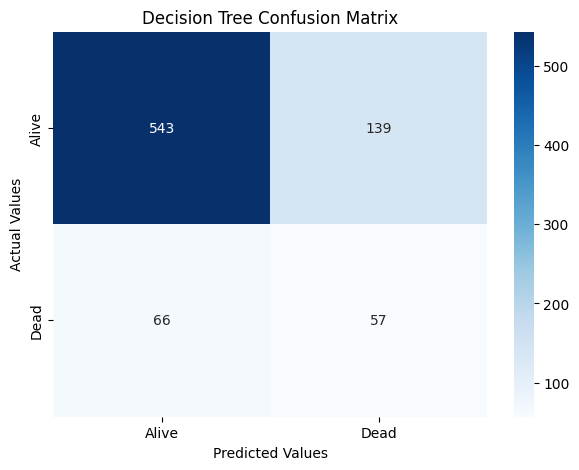

In [21]:

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["Alive", "Dead"]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Alive", "Dead"],
    yticklabels=["Alive", "Dead"]
)

plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.title("Decision Tree Confusion Matrix")

plt.show()


In [22]:

print(classification_report(y_test, y_pred))


              precision    recall  f1-score   support

       Alive       0.89      0.80      0.84       682
        Dead       0.29      0.46      0.36       123

    accuracy                           0.75       805
   macro avg       0.59      0.63      0.60       805
weighted avg       0.80      0.75      0.77       805



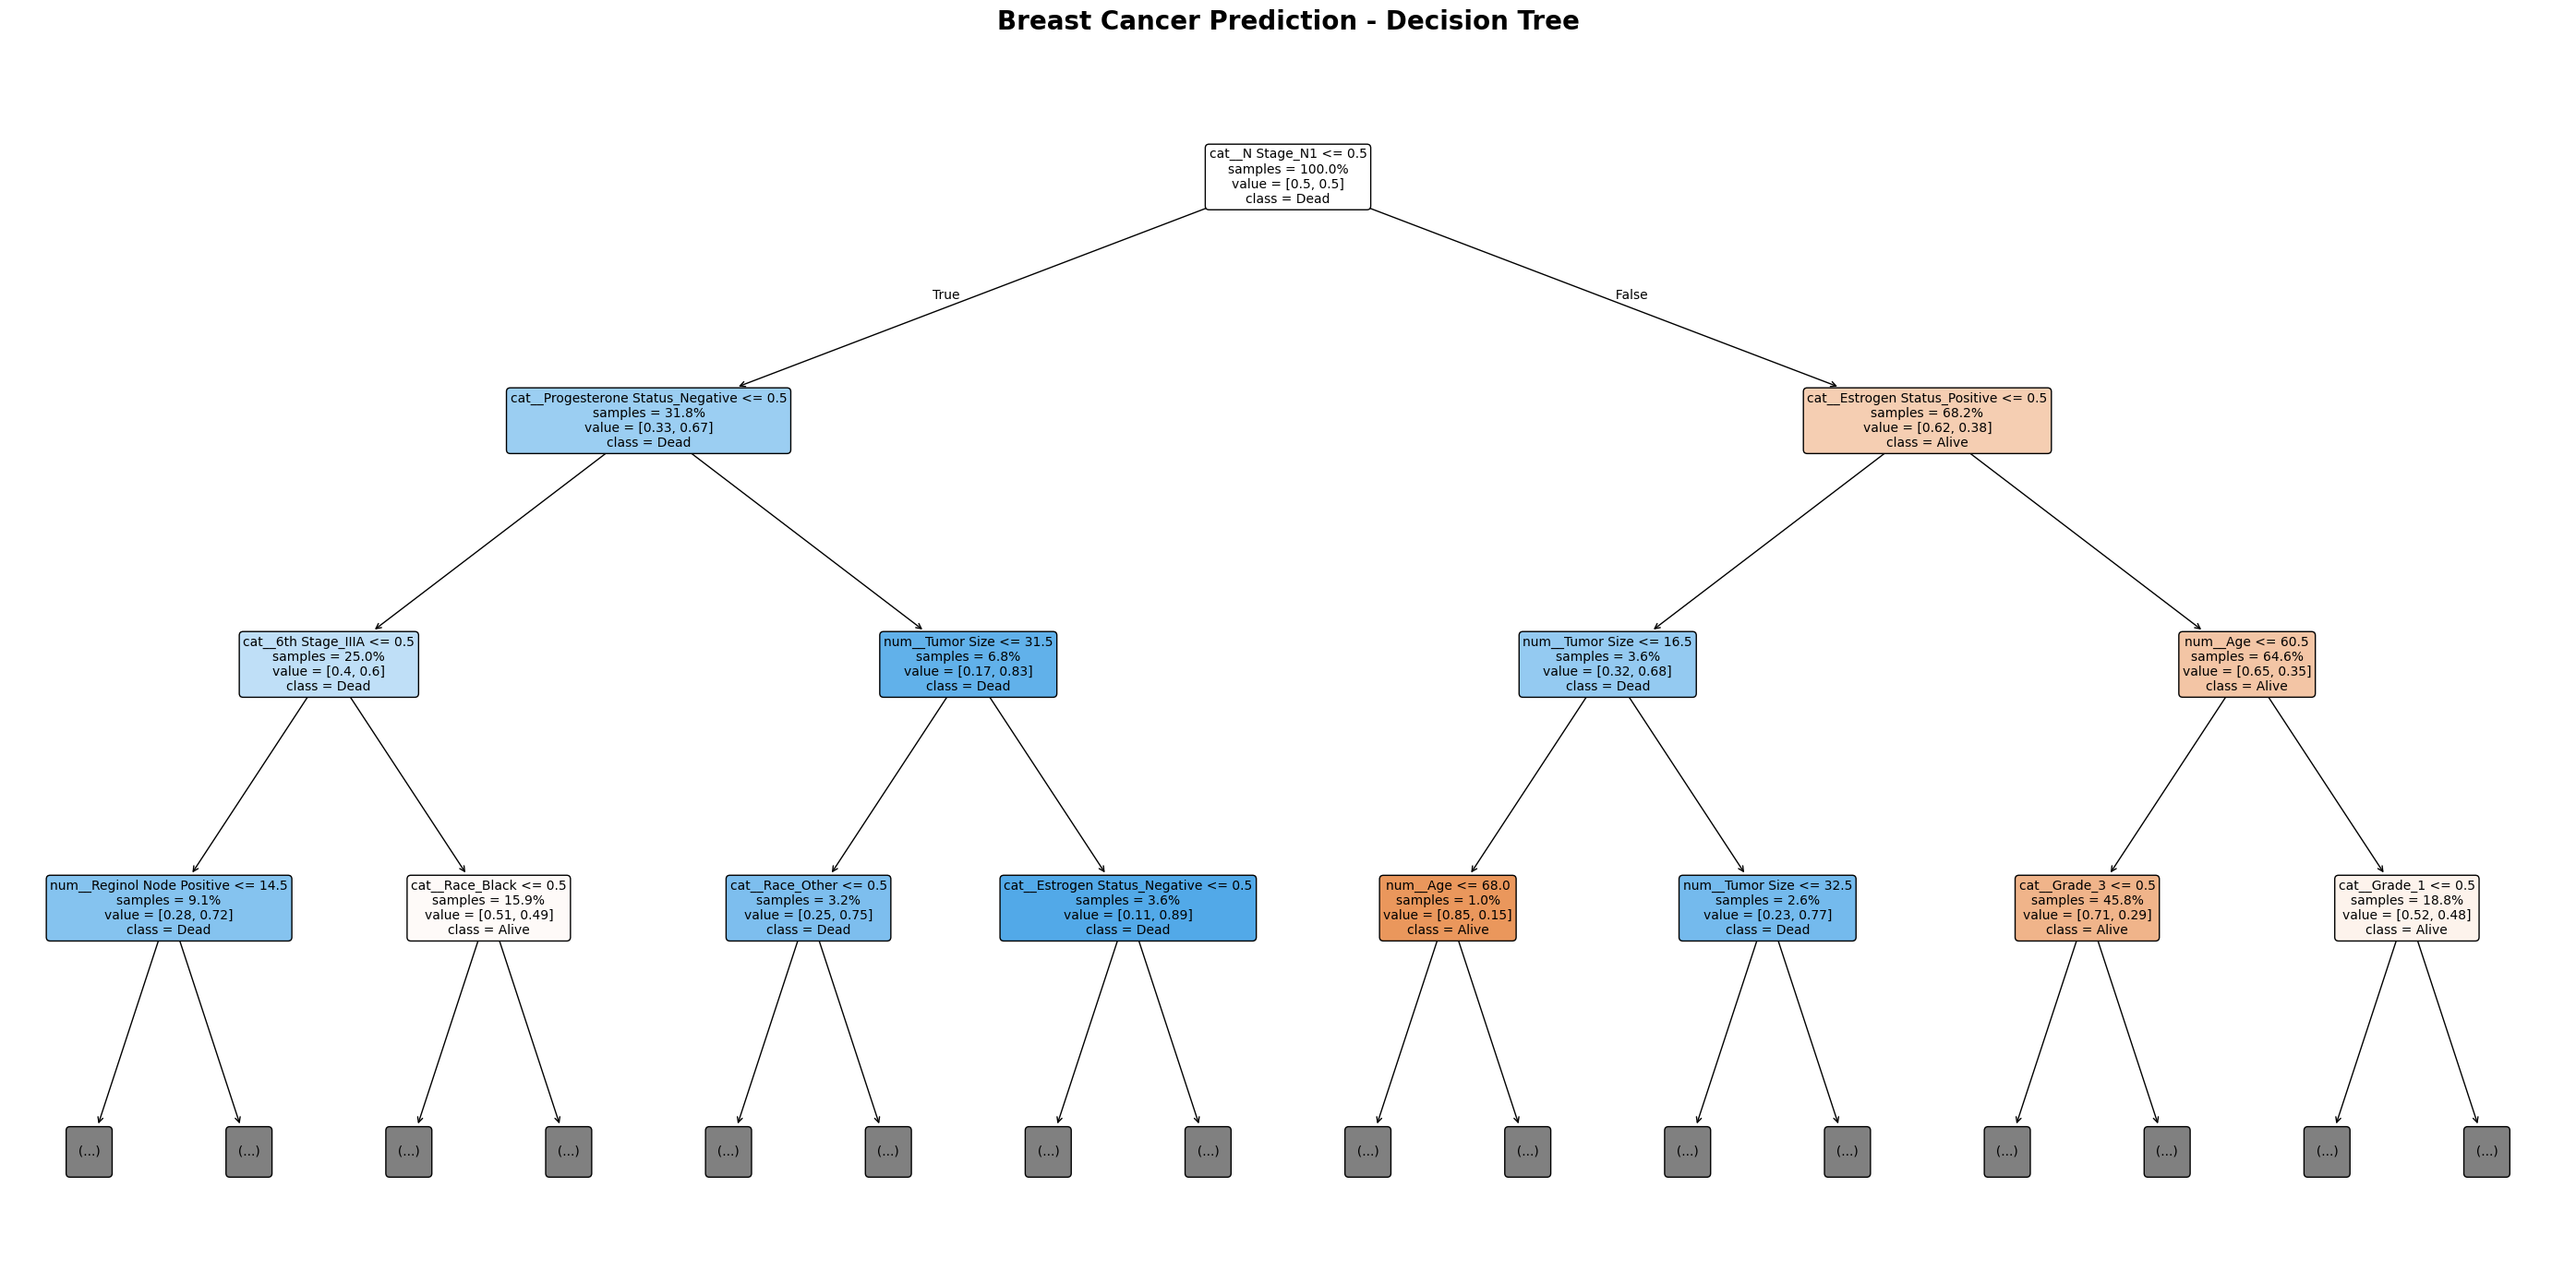

In [23]:

# Extract trained Decision Tree
tree = model.named_steps["tree"]

# Get actual feature names after One-Hot Encoding
feature_names = model.named_steps[
    "preprocess"
].get_feature_names_out()

# Get class names
class_names = [str(c) for c in tree.classes_]

# Set figure size
plt.figure(figsize=(28, 14))

# Plot the tree
plot_tree(
    tree,
    feature_names=feature_names,
    class_names=class_names,
    filled=True,
    rounded=True,
    fontsize=10,
    max_depth=3,
    impurity=False,
    proportion=True,
    precision=2
)

plt.title(
    "Breast Cancer Prediction - Decision Tree",
    fontsize=20,
    fontweight="bold",
    pad=20
)

plt.tight_layout()
plt.show()


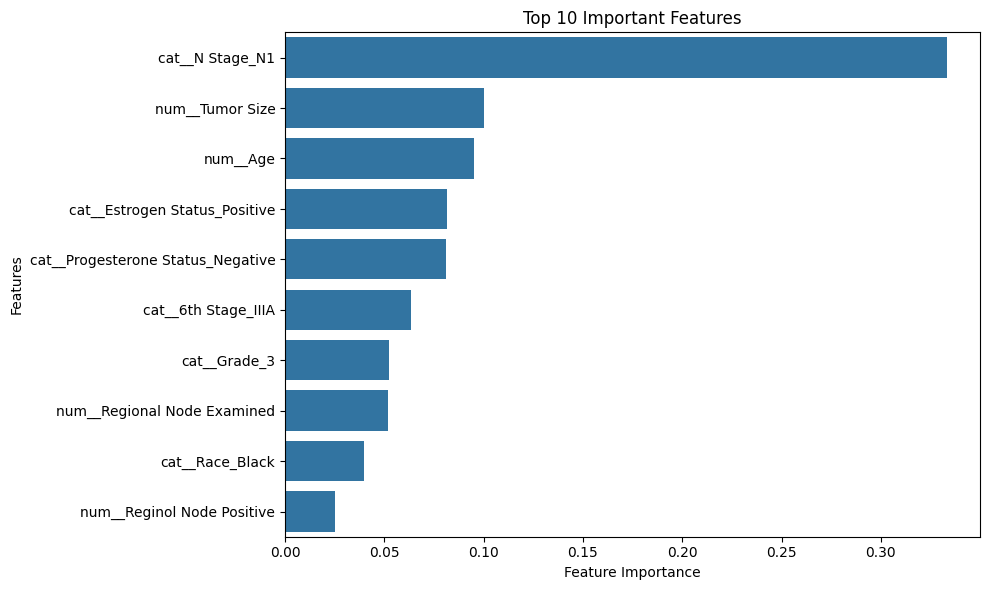

In [24]:

importance = tree.feature_importances_

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# Display top 10 features
top_features = feature_importance.head(10)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Important Features")
plt.xlabel("Feature Importance")
plt.ylabel("Features")

plt.tight_layout()
plt.show()
